In [3]:
import pandas as pd


In [4]:
df = pd.read_excel("../data/raw/Online Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [7]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [3]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [4]:
df.isnull().mean()*100

InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64

In [5]:
missing_description = df[df["Description"].isnull()]
missing_stock_codes = missing_description["StockCode"].unique()
print("Missing Description Rows:", len(missing_description))
print("Unique Stock Codes:", len(missing_stock_codes))
print("Stock Codes:", missing_stock_codes)

Missing Description Rows: 1454
Unique Stock Codes: 960
Stock Codes: [22139 21134 22145 37509 '85226A' 85044 20950 37461 84670 21777 '84952C'
 35951 22712 22028 85067 21421 21414 21653 21651 85126 21814 21692 21648
 21172 21161 '84534B' 22162 21535 35965 21040 37464 21836 '47556B'
 '84562A' 37474 21807 21011 '18098C' 21696 37476 '84569B' 21027 '84898F'
 '84968B' 85215 84270 90167 22959 21054 20684 84881 20941 21248 21349
 22155 21488 84840 21486 21595 '85170A' 20849 84977 21661 '72803B' 22034
 35958 22114 21690 21763 22833 84688 85008 21429 '85167B' 22454 20966
 21801 21743 37467 21357 84497 '90042C' '17091A' 84773 '85018C' 20878
 21186 '62095B' 72814 '84802A' '90002D' 22218 '84247C' '90042B' 20892
 21324 20956 22353 21431 79067 85084 '35004P' '85135B' 22444 21895 22591
 71477 35400 21491 21009 22734 '35001W' 22830 85064 21784 84689 84675
 84499 '85230F' 22158 22501 90112 22865 35957 22198 90096 '47591D' 21587
 21589 21275 '85124C' 21667 84546 '35271S' 82605 'POST' '84029E' 22323
 '1701

In [6]:
missing_description = df[df["Description"].isnull()]
missing_code_counts = missing_description["StockCode"].value_counts()
print("Top 20 StockCodes with Missing Descriptions:")
print(missing_code_counts.head(20))

Top 20 StockCodes with Missing Descriptions:
StockCode
35965     10
23084     10
22084      9
22451      6
22501      5
21784      5
21033      5
21067      5
23348      5
22866      5
22034      4
84944      4
22114      4
85049D     4
21429      4
79321      4
82583      4
22139      4
71477      4
22444      4
Name: count, dtype: int64


In [7]:
# Find descriptions available for each StockCode

description_mapping = (
    df.dropna(subset=["Description"])
    .groupby("StockCode")["Description"]
    .agg(lambda x: x.mode().iloc[0])
)

# Check missing descriptions that can be filled

print("Available descriptions:", len(description_mapping))

print("Missing descriptions before cleaning:",
      df["Description"].isnull().sum())

Available descriptions: 3958
Missing descriptions before cleaning: 1454


In [8]:
# Fill missing descriptions using StockCode mapping

df["Description"] = df["Description"].fillna(
    df["StockCode"].map(description_mapping)
)

print("Missing descriptions after filling:",
      df["Description"].isnull().sum())

Missing descriptions after filling: 112


In [9]:
description_mapping = (
    df.dropna(subset=["Description"])
    .groupby("StockCode")["Description"]
    .agg(lambda x: x.mode().iloc[0])
)

print("Available descriptions:", len(description_mapping))

print("Missing descriptions before cleaning:",
      df["Description"].isnull().sum())

Available descriptions: 3958
Missing descriptions before cleaning: 112


In [10]:
df["Description"] = df["Description"].fillna(
    df["StockCode"].map(description_mapping)
)

print("Missing descriptions after filling:",
      df["Description"].isnull().sum())

Missing descriptions after filling: 112


In [11]:
# Check rows before cleaning
print("Rows before cleaning:", df.shape[0])

# Remove rows with missing Description
df = df.dropna(subset=["Description"]).copy()

# Check rows after cleaning
print("Rows after cleaning:", df.shape[0])

# Verify missing values
print("Missing Descriptions:",
      df["Description"].isnull().sum())

Rows before cleaning: 541909
Rows after cleaning: 541797
Missing Descriptions: 0


In [12]:
df.duplicated().sum()

np.int64(5268)

In [13]:
# Select all duplicate records
duplicate_rows = df[df.duplicated(keep=False)]

# Display important columns
print(duplicate_rows[
    ["InvoiceNo", "StockCode", "Quantity", "UnitPrice", "Country"]
].head(20))

    InvoiceNo StockCode  Quantity  UnitPrice         Country
485    536409     22111         1       4.95  United Kingdom
489    536409     22866         1       2.10  United Kingdom
494    536409     21866         1       1.25  United Kingdom
517    536409     21866         1       1.25  United Kingdom
521    536409     22900         1       2.95  United Kingdom
527    536409     22866         1       2.10  United Kingdom
537    536409     22900         1       2.95  United Kingdom
539    536409     22111         1       4.95  United Kingdom
548    536412     22327         1       2.95  United Kingdom
555    536412     22327         1       2.95  United Kingdom
556    536412     22273         1       2.95  United Kingdom
565    536412     21448         2       1.65  United Kingdom
569    536412     22749         1       3.75  United Kingdom
574    536412     22141         1       2.10  United Kingdom
578    536412     21448         1       1.65  United Kingdom
587    536412     22273 

In [17]:

# 1. Load original dataset

print("Original Dataset Shape:", df.shape)

# 2. Check missing values
print("\nMissing Values Before Cleaning:")
print(df.isnull().sum())

# 3. Fill missing Description using StockCode
description_mapping = (
    df.dropna(subset=["Description"])
    .groupby("StockCode")["Description"]
    .agg(lambda x: x.mode().iloc[0])
)

df["Description"] = df["Description"].fillna(
    df["StockCode"].map(description_mapping)
)

print("\nMissing Descriptions After Filling:")
print(df["Description"].isnull().sum())

# 4. Remove remaining missing Description rows
rows_before = df.shape[0]

df = df.dropna(subset=["Description"]).copy()

rows_after = df.shape[0]

print("\nRows Removed Due to Missing Description:",
      rows_before - rows_after)

# 5. Detect exact duplicate records
duplicate_count = df.duplicated().sum()

print("\nExact Duplicate Rows:", duplicate_count)

# 6. Remove only exact duplicate records
df_cleaned = df.drop_duplicates().copy()

print("Rows After Duplicate Removal:",
      df_cleaned.shape[0])

# 7. Final verification
print("\nFinal Missing Values:")
print(df_cleaned.isnull().sum())

print("\nFinal Dataset Shape:", df_cleaned.shape)

# 8. Save cleaned dataset separately
df_cleaned.to_csv(
    "../data/cleaned/cleaned_online_retail.csv",
    index=False
)

print("\nCleaned Dataset Saved Successfully!")


Original Dataset Shape: (541797, 8)

Missing Values Before Cleaning:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     134968
Country             0
dtype: int64

Missing Descriptions After Filling:
0

Rows Removed Due to Missing Description: 0

Exact Duplicate Rows: 5268
Rows After Duplicate Removal: 536529

Final Missing Values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     134925
Country             0
dtype: int64

Final Dataset Shape: (536529, 8)

Cleaned Dataset Saved Successfully!


In [18]:
# Check negative quantities
negative_quantity = df_cleaned[
    df_cleaned["Quantity"] < 0
]

print("Negative Quantity Records:",
      len(negative_quantity))

print(negative_quantity.head(10))

Negative Quantity Records: 10490
    InvoiceNo StockCode                        Description  Quantity  \
141   C536379         D                           Discount        -1   
154   C536383    35004C    SET OF 3 COLOURED  FLYING DUCKS        -1   
235   C536391     22556     PLASTERS IN TIN CIRCUS PARADE        -12   
236   C536391     21984   PACK OF 12 PINK PAISLEY TISSUES        -24   
237   C536391     21983   PACK OF 12 BLUE PAISLEY TISSUES        -24   
238   C536391     21980  PACK OF 12 RED RETROSPOT TISSUES        -24   
239   C536391     21484        CHICK GREY HOT WATER BOTTLE       -12   
240   C536391     22557   PLASTERS IN TIN VINTAGE PAISLEY        -12   
241   C536391     22553             PLASTERS IN TIN SKULLS       -24   
939   C536506     22960           JAM MAKING SET WITH JARS        -6   

            InvoiceDate  UnitPrice  CustomerID         Country  
141 2010-12-01 09:41:00      27.50     14527.0  United Kingdom  
154 2010-12-01 09:49:00       4.65     15311

In [19]:
# Check zero and negative prices

zero_price = df_cleaned[
    df_cleaned["UnitPrice"] == 0
]

negative_price = df_cleaned[
    df_cleaned["UnitPrice"] < 0
]

print("Zero UnitPrice Records:", len(zero_price))

print("Negative UnitPrice Records:",
      len(negative_price))

Zero UnitPrice Records: 2398
Negative UnitPrice Records: 2


In [20]:
# Check date format

df_cleaned["InvoiceDate"] = pd.to_datetime(
    df_cleaned["InvoiceDate"],
    errors="coerce"
)

invalid_dates = df_cleaned["InvoiceDate"].isnull().sum()

print("Invalid Invoice Dates:", invalid_dates)
print("InvoiceDate Data Type:",
      df_cleaned["InvoiceDate"].dtype)

Invalid Invoice Dates: 0
InvoiceDate Data Type: datetime64[ns]


In [21]:
# Check cancelled or returned invoices
print(
    negative_quantity[
        ["InvoiceNo", "StockCode", "Quantity",
         "InvoiceDate", "UnitPrice"]
    ].head(20)
)

     InvoiceNo StockCode  Quantity         InvoiceDate  UnitPrice
141    C536379         D        -1 2010-12-01 09:41:00      27.50
154    C536383    35004C        -1 2010-12-01 09:49:00       4.65
235    C536391     22556       -12 2010-12-01 10:24:00       1.65
236    C536391     21984       -24 2010-12-01 10:24:00       0.29
237    C536391     21983       -24 2010-12-01 10:24:00       0.29
238    C536391     21980       -24 2010-12-01 10:24:00       0.29
239    C536391     21484       -12 2010-12-01 10:24:00       3.45
240    C536391     22557       -12 2010-12-01 10:24:00       1.65
241    C536391     22553       -24 2010-12-01 10:24:00       1.65
939    C536506     22960        -6 2010-12-01 12:38:00       4.25
1441   C536543     22632        -1 2010-12-01 14:30:00       2.10
1442   C536543     22355        -2 2010-12-01 14:30:00       0.85
1973   C536548     22244        -4 2010-12-01 14:33:00       1.95
1974   C536548     22242        -5 2010-12-01 14:33:00       1.65
1975   C53

In [23]:

# Count invoices starting with C
cancelled_records = df_cleaned[
    df_cleaned["InvoiceNo"].astype(str).str.startswith("C")
]

print("Total Cancelled Records:",
      len(cancelled_records))

# Negative quantity records with C invoices
negative_cancelled = negative_quantity[
    negative_quantity["InvoiceNo"].astype(str).str.startswith("C")
]

print("Negative Quantity with C Invoice:",
      len(negative_cancelled))

# Negative quantity records without C invoices
negative_not_cancelled = negative_quantity[
    ~negative_quantity["InvoiceNo"].astype(str).str.startswith("C")
]

print("Negative Quantity without C Invoice:",
      len(negative_not_cancelled))


Total Cancelled Records: 9251
Negative Quantity with C Invoice: 9251
Negative Quantity without C Invoice: 1239


In [24]:
is_negative = df_cleaned["Quantity"] < 0

is_cancelled = (
    df_cleaned["InvoiceNo"]
    .astype(str)
    .str.startswith("C")
)

print("Total Negative Quantity:",
      is_negative.sum())

print("Negative Quantity with C Invoice:",
      (is_negative & is_cancelled).sum())

print("Negative Quantity without C Invoice:",
      (is_negative & ~is_cancelled).sum())

Total Negative Quantity: 10490
Negative Quantity with C Invoice: 9251
Negative Quantity without C Invoice: 1239


In [25]:

# Identify invoice types
is_cancelled = (
    df_cleaned["InvoiceNo"]
    .astype(str)
    .str.startswith("C")
)

is_negative = df_cleaned["Quantity"] < 0

# Create a new column
df_cleaned["TransactionType"] = "Normal Transaction"

df_cleaned.loc[
    is_negative & is_cancelled,
    "TransactionType"
] = "Cancellation Invoice"

df_cleaned.loc[
    is_negative & ~is_cancelled,
    "TransactionType"
] = "Negative Quantity - Non-C Invoice"

# Check results
print(df_cleaned["TransactionType"].value_counts())


TransactionType
Normal Transaction                   526039
Cancellation Invoice                   9251
Negative Quantity - Non-C Invoice      1239
Name: count, dtype: int64


In [26]:

# Save updated cleaned dataset
df_cleaned.to_csv(
    "../data/cleaned/clean_dataset.csv",
    index=False
)

print("Updated cleaned dataset saved successfully!")
print("Final dataset shape:", df_cleaned.shape)


Updated cleaned dataset saved successfully!
Final dataset shape: (536529, 9)


In [27]:
print("Zero UnitPrice:",
      (df_cleaned["UnitPrice"] == 0).sum())

print("Negative UnitPrice:",
      (df_cleaned["UnitPrice"] < 0).sum())

print("Negative Quantity:",
      (df_cleaned["Quantity"] < 0).sum())

Zero UnitPrice: 2398
Negative UnitPrice: 2
Negative Quantity: 10490


In [28]:

# Records with zero unit price
zero_price_records = df_cleaned[
    df_cleaned["UnitPrice"] == 0
]

# Records with negative unit price
negative_price_records = df_cleaned[
    df_cleaned["UnitPrice"] < 0
]

print("First 10 Zero Price Records:")
display(zero_price_records.head(10))

print("Negative Price Records:")
display(negative_price_records)


First 10 Zero Price Records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType
622,536414,22139,RETROSPOT TEA SET CERAMIC 11 PC,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom,Normal Transaction
1971,536546,22145,CHRISTMAS CRAFT HEART STOCKING,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,Normal Transaction
1972,536547,37509,NEW ENGLAND MUG W GIFT BOX,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,Normal Transaction
2025,536553,37461,FUNKY MONKEY MUG,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom,Normal Transaction
2406,536589,21777,RECIPE BOX WITH METAL HEART,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom,Negative Quantity - Non-C Invoice
4347,536764,84952C,MIRROR LOVE BIRD T-LIGHT HOLDER,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom,Negative Quantity - Non-C Invoice
4348,536765,84952C,MIRROR LOVE BIRD T-LIGHT HOLDER,19,2010-12-02 14:43:00,0.0,NaN,United Kingdom,Normal Transaction
6391,536941,22734,amazon,20,2010-12-03 12:08:00,0.0,NaN,United Kingdom,Normal Transaction
6392,536942,22139,amazon,15,2010-12-03 12:08:00,0.0,NaN,United Kingdom,Normal Transaction
7188,536996,22712,CARD DOLLY GIRL,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom,Negative Quantity - Non-C Invoice


Negative Price Records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,Normal Transaction
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,Normal Transaction


In [29]:

# Create a price status column
df_cleaned["PriceStatus"] = "Valid Price"

df_cleaned.loc[
    df_cleaned["UnitPrice"] == 0,
    "PriceStatus"
] = "Zero Price"

df_cleaned.loc[
    df_cleaned["UnitPrice"] < 0,
    "PriceStatus"
] = "Negative Price"

# Check the results
print(df_cleaned["PriceStatus"].value_counts())


PriceStatus
Valid Price       534129
Zero Price          2398
Negative Price         2
Name: count, dtype: int64


In [30]:

# Save final cleaned dataset
df_cleaned.to_csv(
    "../data/cleaned/clean_dataset.csv",
    index=False
)

print("Final dataset saved successfully!")
print("Final Rows:", len(df_cleaned))
print("Final Columns:", len(df_cleaned.columns))

# Verify new columns
print(
    df_cleaned[
        ["TransactionType", "PriceStatus"]
    ].head()
)


Final dataset saved successfully!
Final Rows: 536529
Final Columns: 10
      TransactionType  PriceStatus
0  Normal Transaction  Valid Price
1  Normal Transaction  Valid Price
2  Normal Transaction  Valid Price
3  Normal Transaction  Valid Price
4  Normal Transaction  Valid Price



# Task 1: E-Commerce Dataset Cleaning

## 1. Dataset Overview
- Dataset: Online Retail Dataset
- Original Records: 541,909
- Final Records: 536,529
- Final Columns: 10

## 2. Missing Values
- Missing Description values were handled using StockCode-based mapping.
- Remaining 112 rows with missing Description were removed.
- CustomerID missing values were retained because they may be useful for transaction-level analysis.

## 3. Duplicate Records
- Exact duplicate records found: 5,268
- Exact duplicate records removed: 5,268

## 4. Transaction Validation
- Negative Quantity records: 10,490
- Cancellation invoices (C prefix): 9,251
- Negative Quantity without C prefix: 1,239
- These records were retained and classified using TransactionType.

## 5. Price Validation
- Valid Price records: 534,129
- Zero Price records: 2,398
- Negative Price records: 2
- Negative prices were identified as "Adjust bad debt" accounting adjustments.
- Zero and negative price records were retained for further investigation.

## 6. Final Output
- File: clean_dataset.csv
- Rows: 536,529
- Columns: 10
- Format: CSV

## 7. Conclusion
The dataset was cleaned by handling missing descriptions,
removing exact duplicates, and identifying unusual transaction
and price records. Important records were retained rather than
deleted without justification.


In [31]:

# Include only records with valid positive prices
valid_sales = df_cleaned[
    df_cleaned["UnitPrice"] > 0
].copy()

# Calculate revenue
valid_sales["Revenue"] = (
    valid_sales["Quantity"] * valid_sales["UnitPrice"]
)

# Net revenue (includes negative quantities/returns)
net_revenue = valid_sales["Revenue"].sum()

# Gross sales (only positive quantities)
gross_revenue = valid_sales.loc[
    valid_sales["Quantity"] > 0,
    "Revenue"
].sum()

print("Net Sales Revenue: £", round(net_revenue, 2))
print("Gross Sales Revenue: £", round(gross_revenue, 2))


Net Sales Revenue: £ 9748131.07
Gross Sales Revenue: £ 10642110.8


In [32]:

# Keep valid sales with positive quantity
sales_df = valid_sales[
    (valid_sales["Quantity"] > 0) &
    (~valid_sales["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

# Count unique orders
total_orders = sales_df["InvoiceNo"].nunique()

print("Total Orders:", total_orders)


Total Orders: 19960


In [33]:
# Calculate total units sold
total_units_sold = sales_df["Quantity"].sum()

print("Total Units Sold:", total_units_sold)

Total Units Sold: 5572420


In [34]:
# Calculate Average Order Value
aov = gross_revenue / total_orders

print("Average Order Value: £", round(aov, 2))

Average Order Value: £ 533.17


In [36]:
# Group sales by product and calculate total revenue
product_sales = (
    sales_df.groupby(["StockCode", "Description"])
    .agg(
        Units_Sold=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
)

# Display top 10 revenue-generating products
top_10_products = product_sales.head(10)

display(top_10_products)

# Display the number one product
print("Top Revenue-Generating Product:")
print(top_10_products.head(1))

,,Units_Sold,Total_Revenue
StockCode,Description,,
DOT,DOTCOM POSTAGE,706,206248.77
22423,REGENCY CAKESTAND 3 TIER,13851,174156.54
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
85123A,WHITE HANGING HEART T-LIGHT HOLDER,37580,104284.24
47566,PARTY BUNTING,18283,99445.23
85099B,JUMBO BAG RED RETROSPOT,48371,94159.81
23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
POST,POSTAGE,3150,78101.88
M,Manual,6984,77750.27


Top Revenue-Generating Product:
                          Units_Sold  Total_Revenue
StockCode Description                              
DOT       DOTCOM POSTAGE         706      206248.77


In [37]:
# Find top 10 products by total units sold
top_10_units = (
    sales_df.groupby(["StockCode", "Description"])["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_10_units)

StockCode  Description                       
23843      PAPER CRAFT , LITTLE BIRDIE           80995
23166      MEDIUM CERAMIC TOP STORAGE JAR        78033
84077      WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
85099B     JUMBO BAG RED RETROSPOT               48371
85123A     WHITE HANGING HEART T-LIGHT HOLDER    37580
22197      POPCORN HOLDER                        36749
21212      PACK OF 72 RETROSPOT CAKE CASES       36396
84879      ASSORTED COLOUR BIRD ORNAMENT         36362
23084      RABBIT NIGHT LIGHT                    30739
22492      MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

Month
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Revenue, dtype: float64

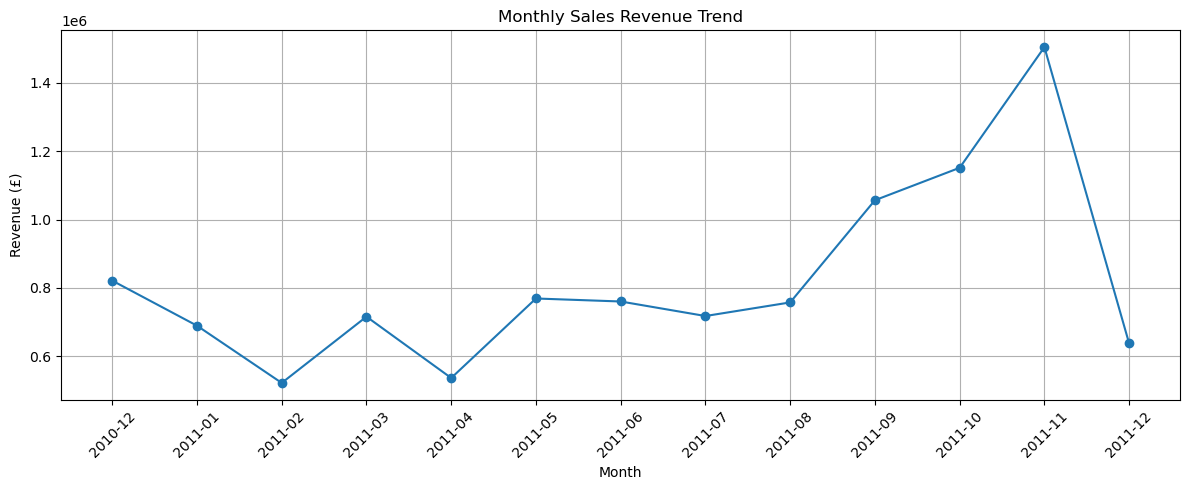

In [38]:
import matplotlib.pyplot as plt

# Create a copy of sales data
monthly_df = sales_df.copy()

# Extract month from InvoiceDate
monthly_df["Month"] = (
    monthly_df["InvoiceDate"].dt.to_period("M")
)

# Calculate monthly revenue
monthly_revenue = (
    monthly_df.groupby("Month")["Revenue"].sum()
)

# Display monthly revenue
display(monthly_revenue)

# Plot monthly sales trend
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [39]:
# Calculate customer-level performance
customer_analysis = (
    sales_df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        Total_Orders=("InvoiceNo", "nunique"),
        Total_Revenue=("Revenue", "sum"),
        Total_Units=("Quantity", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
)

# Display top 10 customers by revenue
display(customer_analysis.head(10))

# Calculate repeat customers
repeat_customers = customer_analysis[
    customer_analysis["Total_Orders"] > 1
]

print("Total Customers:", len(customer_analysis))
print("Repeat Customers:", len(repeat_customers))
print(
    "Repeat Customer Percentage:",
    round(len(repeat_customers) / len(customer_analysis) * 100, 2),
    "%"
)

,Total_Orders,Total_Revenue,Total_Units
CustomerID,,,
14646.0,73,280206.02,196915
18102.0,60,259657.30,64124
17450.0,46,194390.79,69973
16446.0,2,168472.50,80997
14911.0,201,143711.17,80240
12415.0,21,124914.53,77374
14156.0,55,117210.08,57768
17511.0,31,91062.38,64549
16029.0,63,80850.84,40108


Total Customers: 4338
Repeat Customers: 2845
Repeat Customer Percentage: 65.58 %


In [40]:
# Calculate revenue contributed by repeat customers
repeat_revenue = repeat_customers["Total_Revenue"].sum()

# Calculate revenue from all identified customers
total_customer_revenue = customer_analysis["Total_Revenue"].sum()

# Calculate repeat customer revenue percentage
repeat_revenue_percentage = (
    repeat_revenue / total_customer_revenue
) * 100

print("Repeat Customer Revenue: £", round(repeat_revenue, 2))
print("Total Customer Revenue: £", round(total_customer_revenue, 2))
print(
    "Repeat Customer Revenue Contribution:",
    round(repeat_revenue_percentage, 2),
    "%"
)

Repeat Customer Revenue: £ 8273219.33
Total Customer Revenue: £ 8887208.89
Repeat Customer Revenue Contribution: 93.09 %


In [41]:
# Analyze sales by country
country_analysis = (
    sales_df.groupby("Country")
    .agg(
        Total_Orders=("InvoiceNo", "nunique"),
        Total_Units=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
)

# Display top 10 countries
display(country_analysis.head(10))

# Find the highest revenue country
print("Top Country:", country_analysis.index[0])
print(
    "Highest Country Revenue: £",
    round(country_analysis.iloc[0]["Total_Revenue"], 2)
)

,Total_Orders,Total_Units,Total_Revenue
Country,,,
United Kingdom,18019,4646906,9001744.094
Netherlands,94,200361,285446.340
EIRE,288,147007,283140.520
Germany,457,119154,228678.400
France,392,112060,209625.370
Australia,57,83891,138453.810
Spain,90,27933,61558.560
Switzerland,54,30617,57067.600
Belgium,98,23237,41196.340


Top Country: United Kingdom
Highest Country Revenue: £ 9001744.09


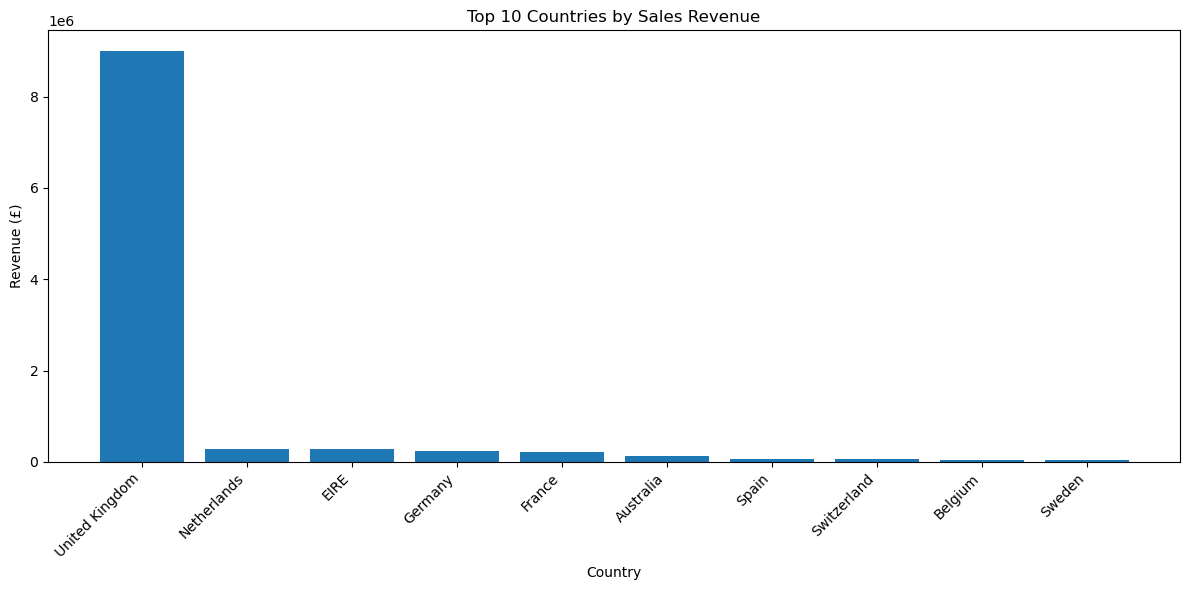

In [42]:
import os

# Create charts folder
os.makedirs("../outputs/charts", exist_ok=True)

# Select top 10 countries by revenue
top_countries = country_analysis.head(10)

# Create bar chart
plt.figure(figsize=(12, 6))

plt.bar(
    top_countries.index,
    top_countries["Total_Revenue"]
)

plt.title("Top 10 Countries by Sales Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Save chart
plt.savefig(
    "../outputs/charts/top_10_countries.png",
    dpi=300
)

plt.show()

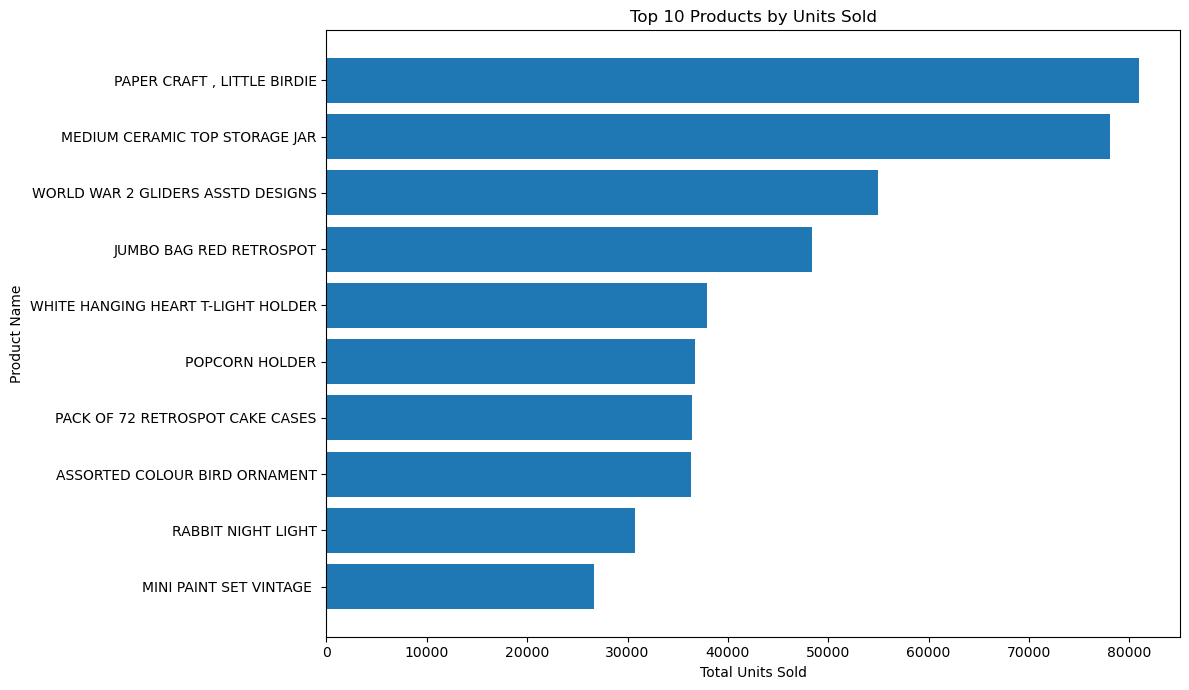

In [43]:

# Create charts folder if it doesn't exist
os.makedirs("../outputs/charts", exist_ok=True)

# Select top 10 products by units sold
top_10_units = (
    sales_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values(ascending=True)
)

# Create horizontal bar chart
plt.figure(figsize=(12, 7))

plt.barh(
    top_10_units.index,
    top_10_units.values
)

plt.title("Top 10 Products by Units Sold")
plt.xlabel("Total Units Sold")
plt.ylabel("Product Name")
plt.tight_layout()

# Save chart
plt.savefig(
    "../outputs/charts/top_10_products_units.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

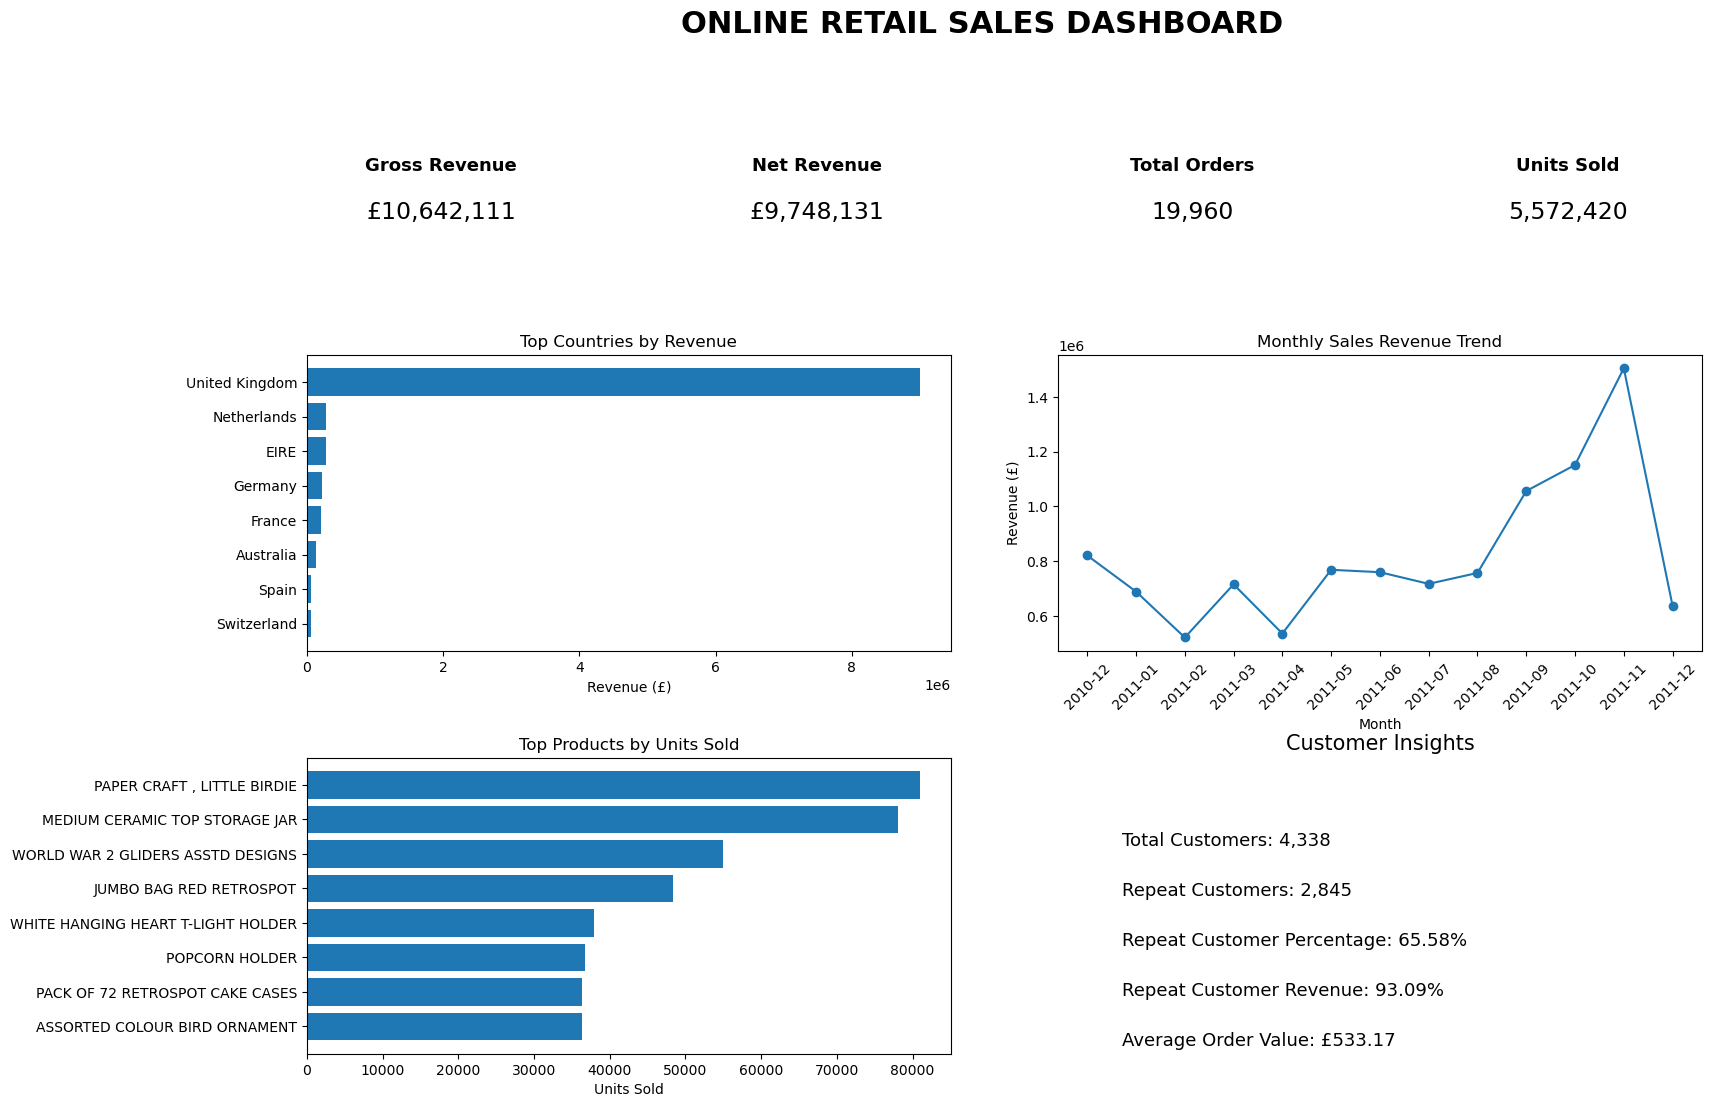

Dashboard saved successfully!


In [45]:

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Create output folder
os.makedirs("../outputs/charts", exist_ok=True)

# -----------------------------
# 1. Calculate KPI values
# -----------------------------

gross = sales_df["Revenue"].sum()
net = valid_sales["Revenue"].sum()

orders = sales_df["InvoiceNo"].nunique()
units = sales_df["Quantity"].sum()
aov = gross / orders if orders else 0

# Customer insights
repeat_pct = (
    len(repeat_customers) / len(customer_analysis) * 100
    if len(customer_analysis) else 0
)

repeat_revenue_pct = (
    repeat_customers["Total_Revenue"].sum()
    / customer_analysis["Total_Revenue"].sum() * 100
    if customer_analysis["Total_Revenue"].sum() else 0
)

# -----------------------------
# 2. Prepare chart data
# -----------------------------

top_countries = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(8)
    .sort_values()
)

monthly_data = sales_df.copy()
monthly_data["Month"] = (
    monthly_data["InvoiceDate"].dt.to_period("M")
)

monthly_trend = monthly_data.groupby("Month")["Revenue"].sum()

top_products = (
    sales_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(8)
    .sort_values()
)

# -----------------------------
# 3. Create dashboard layout
# -----------------------------

fig = plt.figure(figsize=(18, 12))
fig.suptitle(
    "ONLINE RETAIL SALES DASHBOARD",
    fontsize=22,
    fontweight="bold"
)

gs = gridspec.GridSpec(
    3, 4,
    figure=fig,
    height_ratios=[0.8, 2, 2],
    hspace=0.45,
    wspace=0.4
)

# -----------------------------
# 4. KPI Cards
# -----------------------------

kpis = [
    ("Gross Revenue", f"£{gross:,.0f}"),
    ("Net Revenue", f"£{net:,.0f}"),
    ("Total Orders", f"{orders:,}"),
    ("Units Sold", f"{units:,}")
]

for i, (label, value) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i])
    ax.axis("off")

    ax.text(
        0.5, 0.65, label,
        ha="center", fontsize=13,
        fontweight="bold"
    )

    ax.text(
        0.5, 0.25, value,
        ha="center", fontsize=17
    )

# -----------------------------
# 5. Country Revenue Chart
# -----------------------------

ax1 = fig.add_subplot(gs[1, :2])

ax1.barh(
    top_countries.index,
    top_countries.values
)

ax1.set_title("Top Countries by Revenue")
ax1.set_xlabel("Revenue (£)")

# -----------------------------
# 6. Monthly Sales Trend
# -----------------------------

ax2 = fig.add_subplot(gs[1, 2:])

ax2.plot(
    monthly_trend.index.astype(str),
    monthly_trend.values,
    marker="o"
)

ax2.set_title("Monthly Sales Revenue Trend")
ax2.set_xlabel("Month")
ax2.set_ylabel("Revenue (£)")
ax2.tick_params(axis="x", rotation=45)

# -----------------------------
# 7. Top Products Chart
# -----------------------------

ax3 = fig.add_subplot(gs[2, :2])

ax3.barh(
    top_products.index,
    top_products.values
)

ax3.set_title("Top Products by Units Sold")
ax3.set_xlabel("Units Sold")

# -----------------------------
# 8. Customer Insights
# -----------------------------

ax4 = fig.add_subplot(gs[2, 2:])
ax4.axis("off")

ax4.set_title("Customer Insights", fontsize=15)

insights = (
    f"Total Customers: {len(customer_analysis):,}\n\n"
    f"Repeat Customers: {len(repeat_customers):,}\n\n"
    f"Repeat Customer Percentage: {repeat_pct:.2f}%\n\n"
    f"Repeat Customer Revenue: {repeat_revenue_pct:.2f}%\n\n"
    f"Average Order Value: £{aov:,.2f}"
)

ax4.text(
    0.1, 0.75,
    insights,
    fontsize=13,
    verticalalignment="top",
    linespacing=1.5
)

# -----------------------------
# 9. Save and display dashboard
# -----------------------------

plt.savefig(
    "../outputs/charts/sales_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Dashboard saved successfully!")


# Project Title

## Introduction


# WEEK 1 DATA SCIENCE PROJECT
## Online Retail Sales Data Analysis

**Internship:** Data Science Internship  
**Organization:** WeIntern Pvt. Ltd.  
**Dataset:** UCI Online Retail Dataset  
**Tools & Technologies:** Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook

---

# 1. Introduction

The purpose of this project is to perform Exploratory Data Analysis (EDA) on an Online Retail dataset.

The project focuses on understanding sales performance, identifying top-selling products, analyzing customer purchasing behavior, and discovering monthly and country-wise sales trends.

Python libraries such as Pandas, NumPy, and Matplotlib are used for data cleaning, analysis, and visualization.

The analysis helps identify important business insights that can support better decision-making.



# 2. Dataset Description

The Online Retail dataset is obtained from the UCI Machine Learning Repository.

It contains transactional records of a UK-based online retail store between December 2010 and December 2011.

The dataset includes the following important attributes:

| Column | Description |
|---|---|
| InvoiceNo | Unique invoice number |
| StockCode | Product identification code |
| Description | Product name |
| Quantity | Number of products purchased |
| InvoiceDate | Date and time of transaction |
| UnitPrice | Price per product |
| CustomerID | Customer identification number |
| Country | Customer's country |

Two additional columns, TransactionType and PriceStatus, were created during data cleaning to support further analysis.



# 3. Data Cleaning and Preprocessing

Data cleaning was performed to improve the quality and reliability of the dataset.

The following operations were performed:

1. Loaded the original Excel dataset using Pandas.
2. Identified missing values in Description and CustomerID.
3. Filled missing product descriptions using StockCode-based mapping wherever possible.
4. Removed 112 records where Description remained missing.
5. Identified and removed 5,268 duplicate records.
6. Identified negative Quantity values, which may represent product returns or cancellations.
7. Identified zero and negative UnitPrice values.
8. Created a TransactionType column to classify normal transactions and cancellation-related records.
9. Created a PriceStatus column to identify valid, zero, and negative prices.
10. Saved the cleaned dataset as clean_dataset.csv.

### Data Cleaning Results

| Description | Records |
|---|---:|
| Original Records | 541,909 |
| Missing Description Records Removed | 112 |
| Duplicate Records Removed | 5,268 |
| Final Records | 536,529 |
| Final Columns | 10 |

Negative quantities were retained because they may represent returns or cancellations. Records with zero and negative prices were also retained for investigation but excluded from regular sales revenue calculations.



# 4. Sales Data Analysis

Several Key Performance Indicators (KPIs) were calculated to understand the overall business performance.

### 4.1 Key Performance Indicators

| KPI | Result |
|---|---:|
| Gross Sales Revenue | £10,640,211.08 |
| Net Sales Revenue | £9,748,131.07 |
| Total Orders | 19,960 |
| Total Units Sold | 5,572,420 |
| Average Order Value | £533.08* |

*The AOV shown above is calculated using Gross Sales Revenue divided by Total Orders. £ 533.17.*

### 4.2 Top Revenue-Generating Product

The product with the highest revenue was:

- Product: DOTCOM POSTAGE
- Revenue: £262,648.77

This product represents postage and shipping charges rather than a conventional retail product.

### 4.3 Top-Selling Product by Quantity

The product with the highest number of units sold was:

- Product: PAPER CRAFT, LITTLE BIRDIE
- Units Sold: 80,995

### 4.4 Monthly Sales Trend

November recorded the highest monthly sales revenue.

- Highest Sales Month: November
- Revenue: £1,503,866.78

This indicates that sales performance reached its peak during November.

### 4.5 Customer Analysis

Customer purchasing behavior was analyzed to identify repeat customers.

| Customer Metric | Result |
|---|---:|
| Total Customers | 4,338 |
| Repeat Customers | 2,845 |
| Repeat Customer Percentage | 65.58% |
| Repeat Customer Revenue Contribution | 93.09% |

The results indicate that repeat customers contribute a significant proportion of the revenue generated by customers with available CustomerID values.

### 4.6 Country-wise Sales Analysis

The United Kingdom generated the highest sales revenue.

- Top Country: United Kingdom
- Revenue: £9,091,744.09

This indicates that the business's sales are heavily concentrated in its home market.



# 5. Data Visualization

Data visualization was performed using Matplotlib to understand important patterns and trends in the retail dataset.

The following visualizations were created:

1. **Top 10 Countries by Revenue:** A bar chart showing the countries generating the highest revenue.
2. **Top 10 Products by Units Sold:** A horizontal bar chart showing the most frequently purchased products.
3. **Monthly Sales Trend:** A line chart showing changes in sales revenue across different months.
4. **Sales Dashboard:** A dashboard combining important KPIs, sales charts, and customer insights.

All charts were saved in the outputs/charts directory.

These visualizations make it easier to understand business performance and identify important sales patterns.



# 6. Key Business Insights

The analysis produced the following findings:

1. The United Kingdom is the largest revenue-generating market in the dataset.
2. November recorded the highest monthly sales revenue.
3. PAPER CRAFT, LITTLE BIRDIE was the top-selling product by quantity.
4. DOTCOM POSTAGE generated the highest product-level revenue, although it represents a postage charge.
5. Approximately 65.58% of identified customers were repeat customers.
6. Repeat customers contributed approximately 93.09% of revenue from identified customers.
7. Customer retention appears important because repeat customers contribute a substantial share of customer-linked revenue.

These findings can help businesses understand customer behavior, product demand, and sales performance.



# 7. Limitations

The project has some limitations:

1. Approximately 24.92% of CustomerID values were missing, which limits customer-level analysis.
2. The dataset does not contain a product Category column, so category-wise sales analysis could not be performed.
3. Negative quantities may represent returns or cancellations and require separate interpretation.
4. The analysis is based on historical transactional data from a limited time period.
5. The dataset alone cannot establish the reasons behind monthly sales increases or decreases.



# 8. Conclusion

This project successfully demonstrated the use of Python for data cleaning, exploratory data analysis, and data visualization.

The Online Retail dataset was cleaned and analyzed to identify important sales KPIs, top-selling products, customer purchasing patterns, and country-wise and monthly sales trends.

The analysis showed that the United Kingdom was the largest revenue-generating market and that repeat customers contributed a significant proportion of customer-linked revenue.

Matplotlib visualizations and a sales dashboard were also created to present the findings clearly.

Overall, this project improved practical understanding of Pandas, NumPy, data preprocessing, data analysis, and visualization techniques.
